In [1]:
import os, time, itertools, warnings
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, precision_recall_curve)
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope, EmpiricalCovariance
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

SEEDS = [42, 100, 2023, 777, 999, 123, 888, 555, 333, 111]
MAX_TRAIN = 30000
RESUME = True                     # продолжить с места остановки, если файл есть
PARTIAL_FILE = 'results_partial.csv'
K_GRID = [5, 10, 20, 50, 100, 200]  # одинаковая сетка k для KNN и LOF

CONTROL = 'Breast Cancer (контроль)'   # после удаления дубликатов доля "аномалий" ~51%

def load_ad_dataset(dataset_id, name, anomaly_label):
    print(f"Загрузка {name} (ID: {dataset_id})...")
    data = fetch_openml(data_id=dataset_id, as_frame=True, parser='auto')
    X, y = data.data.copy(), data.target.copy()
    X_num = X.select_dtypes(include=[np.number]).copy()
    y_bin = (y == anomaly_label).astype(int)
    n0 = len(X_num)
    mask = ~pd.concat([X_num, y_bin.rename('y')], axis=1).duplicated()   # дубликаты удаляем до разбиения
    X_num = X_num[mask].reset_index(drop=True)
    y_bin = y_bin[mask].reset_index(drop=True)
    print(f"  удалено дубликатов: {n0 - len(X_num)}; признаки: {list(X_num.columns)}")
    return X_num, y_bin

datasets_info = {
    'Credit Card Fraud': {'id': 1597,  'label': '1'},
    'Mammography':       {'id': 310,   'label': '1'},
    'Wilt':              {'id': 40983, 'label': '2'},
    CONTROL:             {'id': 15,    'label': 'malignant'},
    'Ionosphere':        {'id': 59,    'label': 'b'},
}

loaded_datasets, stats = {}, []
for name, info in datasets_info.items():
    X, y = load_ad_dataset(info['id'], name, info['label'])
    loaded_datasets[name] = (X, y)
    stats.append({'Датасет': name, 'Строк (после очистки)': len(X), 'Признаков': X.shape[1],
                  'Аномалий': int(y.sum()), 'Доля (%)': round(100 * y.mean(), 2)})
print("\n--- ХАРАКТЕРИСТИКИ ДАТАСЕТОВ ---")
display(pd.DataFrame(stats))

def prepare_splits(X, y, max_train_samples=MAX_TRAIN, seed=42):
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, random_state=seed, stratify=y)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=seed, stratify=y_tmp)
    if len(X_tr) > max_train_samples:
        X_tr, _, y_tr, _ = train_test_split(X_tr, y_tr, train_size=max_train_samples,
                                            random_state=seed, stratify=y_tr)
    return X_tr, X_va, X_te, y_tr, y_va, y_te

split_rows = []
for name, (X, y) in loaded_datasets.items():
    _, _, _, y_tr, y_va, y_te = prepare_splits(X, y, MAX_TRAIN, 42)
    split_rows.append({'Датасет': name, 'Train': len(y_tr), 'Train аном.': int(y_tr.sum()),
                       'Val': len(y_va), 'Val аном.': int(y_va.sum()),
                       'Test': len(y_te), 'Test аном.': int(y_te.sum())})
print("\n--- РАЗМЕРЫ ВЫБОРОК (seed=42) ---")
display(pd.DataFrame(split_rows))

Загрузка Credit Card Fraud (ID: 1597)...
  удалено дубликатов: 9144; признаки: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
Загрузка Mammography (ID: 310)...
  удалено дубликатов: 3334; признаки: ['attr1', 'attr2', 'attr3', 'attr4', 'attr5', 'attr6']
Загрузка Wilt (ID: 40983)...
  удалено дубликатов: 20; признаки: ['GLCM_Pan', 'Mean_G', 'Mean_R', 'Mean_NIR', 'SD_Plan']
Загрузка Breast Cancer (контроль) (ID: 15)...
  удалено дубликатов: 236; признаки: ['Clump_Thickness', 'Cell_Size_Uniformity', 'Cell_Shape_Uniformity', 'Marginal_Adhesion', 'Single_Epi_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses']
Загрузка Ionosphere (ID: 59)...
  удалено дубликатов: 1; признаки: ['a01', 'a02', 'a03', 'a04', 'a05', 'a06', 'a07', 'a08', 'a09', 'a10', 'a11', 'a12', 'a13', 'a14', 'a15', 'a16', 'a17', 'a18', 'a19', 'a20', 'a21',

,Датасет,Строк (после очистки),Признаков,Аномалий,Доля (%)
0,Credit Card Fraud,275663,29,473,0.17
1,Mammography,7849,6,254,3.24
2,Wilt,4819,5,257,5.33
3,Breast Cancer (контроль),463,9,238,51.40
4,Ionosphere,350,34,125,35.71



--- РАЗМЕРЫ ВЫБОРОК (seed=42) ---


,Датасет,Train,Train аном.,Val,Val аном.,Test,Test аном.
0,Credit Card Fraud,30000,52,55133,95,55133,94
1,Mammography,4709,152,1570,51,1570,51
2,Wilt,2891,154,964,52,964,51
3,Breast Cancer (контроль),277,142,93,48,93,48
4,Ionosphere,210,75,70,25,70,25


In [4]:
class RandomBaseline:
    def __init__(self, random_state=None):
        self.random_state = random_state
        self.rng = np.random.default_rng(random_state)
    def fit(self, X, y=None): return self
    def decision_function(self, X): return -self.rng.random(X.shape[0])
    def get_params(self, deep=True): return {'random_state': self.random_state}

class MahalanobisBaseline:
    def __init__(self): self.cov = EmpiricalCovariance()
    def fit(self, X, y=None): self.cov.fit(X); return self
    def decision_function(self, X): return -self.cov.mahalanobis(X)
    def get_params(self, deep=True): return {}

class KNNAnomaly:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.knn = NearestNeighbors(n_neighbors=n_neighbors, n_jobs=-1)
    def fit(self, X, y=None): self.knn.fit(X); return self
    def decision_function(self, X): return -self.knn.kneighbors(X)[0][:, -1]
    def get_params(self, deep=True): return {'n_neighbors': self.n_neighbors}

algorithms = {
    'Random':            {'class': RandomBaseline,       'grid': [{}]},
    'Mahalanobis':       {'class': MahalanobisBaseline,  'grid': [{}]},
    'Isolation Forest':  {'class': IsolationForest,      'grid': [{'n_estimators': [100, 300], 'max_samples': [256, 1024]}]},
    'LOF':               {'class': LocalOutlierFactor,   'grid': [{'n_neighbors': K_GRID, 'novelty': [True]}]},
    'One-Class SVM':     {'class': OneClassSVM,          'grid': [{'gamma': ['scale', 0.01, 0.1], 'nu': [0.01, 0.05, 0.1, 0.2, 0.4]}]},
    'Elliptic Envelope': {'class': EllipticEnvelope,     'grid': [{'support_fraction': [None, 0.8]}]},
    'KNN':               {'class': KNNAnomaly,           'grid': [{'n_neighbors': K_GRID}]},
}
# gamma='auto' убран: после StandardScaler он совпадает с 'scale'

def expand_grid(g):
    return [dict(zip(g.keys(), p)) for p in itertools.product(*g.values())]

def preprocess(X_tr, X_va, X_te):
    """Всё обучается только на train."""
    imp = SimpleImputer(strategy='median').fit(X_tr)
    A, B, C = imp.transform(X_tr), imp.transform(X_va), imp.transform(X_te)
    sel = VarianceThreshold(0.0).fit(A)
    A, B, C = sel.transform(A), sel.transform(B), sel.transform(C)
    sc = StandardScaler().fit(A)
    return sc.transform(A), sc.transform(B), sc.transform(C)

def evaluate_model(Xtr, Xva, Xte, y_val, y_test, model_class, param_grid, seed):
    base = model_class().get_params()
    grid = [p for g in param_grid for p in expand_grid(g)]
    best = None
    t_tune = time.perf_counter()
    for params in grid:
        params = dict(params)
        if 'n_neighbors' in params and params['n_neighbors'] >= len(Xtr):
            continue
        if 'random_state' in base: params['random_state'] = seed
        if 'n_jobs' in base:       params['n_jobs'] = -1
        model = model_class(**params)
        t0 = time.perf_counter(); model.fit(Xtr); fit_time = time.perf_counter() - t0
        val_scores = -model.decision_function(Xva)
        if not np.isfinite(val_scores).all():
            continue
        ap = average_precision_score(y_val, val_scores)
        if best is None or ap > best['ap']:
            best = dict(ap=ap, model=model, fit_time=fit_time, val_scores=val_scores, params=params)
    tune_time = time.perf_counter() - t_tune
    if best is None:
        return None

    t0 = time.perf_counter()
    test_scores = -best['model'].decision_function(Xte)
    score_time = time.perf_counter() - t0

    # порог 1: максимум F1 на валидации (использует метки val)
    prec, rec, thr = precision_recall_curve(y_val, best['val_scores'])
    f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    thr_f1 = thr[int(np.argmax(f1s))]
    pred = (test_scores >= thr_f1).astype(int)
    # порог 2: только доля аномалий (без поэлементных меток): top-q% по скорам val
    thr_prior = np.quantile(best['val_scores'], 1 - y_val.mean())
    pred_prior = (test_scores >= thr_prior).astype(int)

    return {
        'ROC-AUC': roc_auc_score(y_test, test_scores),
        'PR-AUC': average_precision_score(y_test, test_scores),
        'F1': f1_score(y_test, pred, zero_division=0),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 (порог по доле)': f1_score(y_test, pred_prior, zero_division=0),
        'Naive F1': f1_score(y_test, np.ones_like(y_test), zero_division=0),
        'Val PR-AUC': best['ap'],
        'Fit Time (s)': best['fit_time'],
        'Score Time (s)': score_time,
        'Tuning Time (s)': tune_time,
        'Best params': str({k: v for k, v in best['params'].items() if k not in ('random_state', 'n_jobs')}),
    }

In [5]:
results = []
done_seeds = set()
if RESUME and os.path.exists(PARTIAL_FILE):
    prev = pd.read_csv(PARTIAL_FILE)
    results = prev.to_dict('records')
    done_seeds = set(prev['Seed'].unique())
    print(f"Найдены готовые seed: {sorted(done_seeds)}")

T_ALL = time.time()
for run_idx, seed in enumerate(SEEDS):
    if seed in done_seeds:
        continue
    t_seed = time.time()
    print(f"\n--- ИТЕРАЦИЯ {run_idx + 1}/{len(SEEDS)} (seed {seed}) ---")
    for ds_name, (X, y) in loaded_datasets.items():
        X_tr, X_va, X_te, y_tr, y_va, y_te = prepare_splits(X, y, MAX_TRAIN, seed)
        Xtr, Xva, Xte = preprocess(X_tr, X_va, X_te)
        for algo_name, info in algorithms.items():
            try:
                m = evaluate_model(Xtr, Xva, Xte, y_va, y_te, info['class'], info['grid'], seed)
                if m:
                    m.update({'Dataset': ds_name, 'Algorithm': algo_name, 'Run': run_idx + 1, 'Seed': seed})
                    results.append(m)
            except Exception as e:
                print(f"    ! Ошибка {algo_name} на {ds_name}: {e}")
    pd.DataFrame(results).to_csv(PARTIAL_FILE, index=False, encoding='utf-8-sig')
    print(f"  seed {seed} готов за {(time.time() - t_seed) / 60:.1f} мин")
print(f"\nВсего: {(time.time() - T_ALL) / 60:.1f} мин")

df_results = pd.DataFrame(results)
df_results.to_csv('anomaly_detection_results_raw.csv', index=False, encoding='utf-8-sig')
cnt = df_results.groupby(['Dataset', 'Algorithm']).size()
print(f"Все комбинации выполнены {len(SEEDS)} раз" if (cnt == len(SEEDS)).all() else "ВНИМАНИЕ: есть комбинации с неполным числом прогонов:")
if not (cnt == len(SEEDS)).all(): print(cnt[cnt != len(SEEDS)])


--- ИТЕРАЦИЯ 1/10 (seed 42) ---
  seed 42 готов за 7.2 мин

--- ИТЕРАЦИЯ 2/10 (seed 100) ---
  seed 100 готов за 7.2 мин

--- ИТЕРАЦИЯ 3/10 (seed 2023) ---
  seed 2023 готов за 7.0 мин

--- ИТЕРАЦИЯ 4/10 (seed 777) ---
  seed 777 готов за 7.0 мин

--- ИТЕРАЦИЯ 5/10 (seed 999) ---
  seed 999 готов за 7.0 мин

--- ИТЕРАЦИЯ 6/10 (seed 123) ---
  seed 123 готов за 7.7 мин

--- ИТЕРАЦИЯ 7/10 (seed 888) ---
  seed 888 готов за 7.7 мин

--- ИТЕРАЦИЯ 8/10 (seed 555) ---
  seed 555 готов за 7.6 мин

--- ИТЕРАЦИЯ 9/10 (seed 333) ---
  seed 333 готов за 7.7 мин

--- ИТЕРАЦИЯ 10/10 (seed 111) ---
  seed 111 готов за 7.4 мин

Всего: 73.6 мин
Все комбинации выполнены 10 раз



=== ИТОГОВАЯ ТАБЛИЦА ===


,Dataset,Algorithm,ROC-AUC,PR-AUC,F1,Precision,Recall,F1 (порог по доле),Naive F1,Fit Time (s),Score Time (s),Tuning Time (s)
0,Breast Cancer (контроль),Elliptic Envelope,0.941 ± 0.016,0.933 ± 0.021,0.901 ± 0.019,0.851 ± 0.033,0.960 ± 0.035,0.888 ± 0.022,0.681 ± 0.000,2.962078e-02,0.000320,0.060508
1,Breast Cancer (контроль),Isolation Forest,0.949 ± 0.012,0.943 ± 0.014,0.913 ± 0.016,0.856 ± 0.029,0.979 ± 0.020,0.885 ± 0.037,0.681 ± 0.000,2.200582e-01,0.010982,0.735907
2,Breast Cancer (контроль),KNN,0.975 ± 0.010,0.975 ± 0.012,0.932 ± 0.024,0.910 ± 0.049,0.956 ± 0.027,0.928 ± 0.020,0.681 ± 0.000,6.066000e-04,0.020587,0.102024
3,Breast Cancer (контроль),LOF,0.788 ± 0.029,0.831 ± 0.066,0.774 ± 0.070,0.805 ± 0.072,0.762 ± 0.143,0.769 ± 0.056,0.681 ± 0.000,9.948280e-03,0.006754,0.191346
4,Breast Cancer (контроль),Mahalanobis,0.930 ± 0.018,0.927 ± 0.024,0.888 ± 0.022,0.859 ± 0.027,0.921 ± 0.045,0.886 ± 0.020,0.681 ± 0.000,4.555400e-04,0.000267,0.001666
5,Breast Cancer (контроль),One-Class SVM,0.739 ± 0.044,0.802 ± 0.035,0.707 ± 0.049,0.778 ± 0.122,0.683 ± 0.148,0.714 ± 0.048,0.681 ± 0.000,1.907830e-03,0.000972,0.045817
6,Breast Cancer (контроль),Random,0.520 ± 0.093,0.549 ± 0.071,0.670 ± 0.008,0.516 ± 0.011,0.954 ± 0.039,0.532 ± 0.104,0.681 ± 0.000,6.600007e-07,0.000010,0.001040
7,Credit Card Fraud,Elliptic Envelope,0.928 ± 0.014,0.099 ± 0.016,0.178 ± 0.028,0.155 ± 0.040,0.286 ± 0.169,0.159 ± 0.029,0.003 ± 0.000,2.528745e+00,0.020223,4.764856
8,Credit Card Fraud,Isolation Forest,0.949 ± 0.012,0.196 ± 0.029,0.273 ± 0.041,0.345 ± 0.113,0.257 ± 0.087,0.276 ± 0.047,0.003 ± 0.000,3.672430e-01,0.459450,3.065340
9,Credit Card Fraud,KNN,0.954 ± 0.010,0.182 ± 0.028,0.267 ± 0.047,0.303 ± 0.104,0.316 ± 0.158,0.272 ± 0.046,0.003 ± 0.000,4.322930e-03,1.353740,8.386776



=== ВЫБРАННЫЕ ГИПЕРПАРАМЕТРЫ (частота по seed) ===
Breast Cancer (контроль)     Elliptic Envelope  {"{'support_fraction': None}": 9, "{'support_fraction': 0.8}": 1}
Breast Cancer (контроль)     Isolation Forest   {"{'n_estimators': 300, 'max_samples': 256}": 5, "{'n_estimators': 100, 'max_samples': 256}": 3, "{'n_estimators': 300, 'max_samples': 1024}": 2}
Breast Cancer (контроль)     KNN                {"{'n_neighbors': 100}": 9, "{'n_neighbors': 50}": 1}
Breast Cancer (контроль)     LOF                {"{'n_neighbors': 200, 'novelty': True}": 8, "{'n_neighbors': 100, 'novelty': True}": 2}
Breast Cancer (контроль)     One-Class SVM      {"{'gamma': 'scale', 'nu': 0.4}": 10}
Credit Card Fraud            Elliptic Envelope  {"{'support_fraction': 0.8}": 8, "{'support_fraction': None}": 2}
Credit Card Fraud            Isolation Forest   {"{'n_estimators': 300, 'max_samples': 1024}": 5, "{'n_estimators': 100, 'max_samples': 1024}": 5}
Credit Card Fraud            KNN                {"{'n_

,Dataset,Лучший,Сравнивается с,ΔPR-AUC,p (Wilcoxon)
0,Breast Cancer (контроль),KNN,Elliptic Envelope,0.042,0.0020
1,Breast Cancer (контроль),KNN,Isolation Forest,0.032,0.0020
2,Breast Cancer (контроль),KNN,LOF,0.144,0.0020
3,Breast Cancer (контроль),KNN,Mahalanobis,0.047,0.0020
4,Breast Cancer (контроль),KNN,One-Class SVM,0.173,0.0020
5,Credit Card Fraud,LOF,Elliptic Envelope,0.287,0.0020
6,Credit Card Fraud,LOF,Isolation Forest,0.190,0.0020
7,Credit Card Fraud,LOF,KNN,0.204,0.0020
8,Credit Card Fraud,LOF,Mahalanobis,0.255,0.0020
9,Credit Card Fraud,LOF,One-Class SVM,0.266,0.0020



=== Средний ранг по PR-AUC (1 = лучший) ===
Algorithm
LOF                  3.25
KNN                  3.25
Mahalanobis          3.25
Isolation Forest     3.50
Elliptic Envelope    3.50
One-Class SVM        4.25
dtype: float64


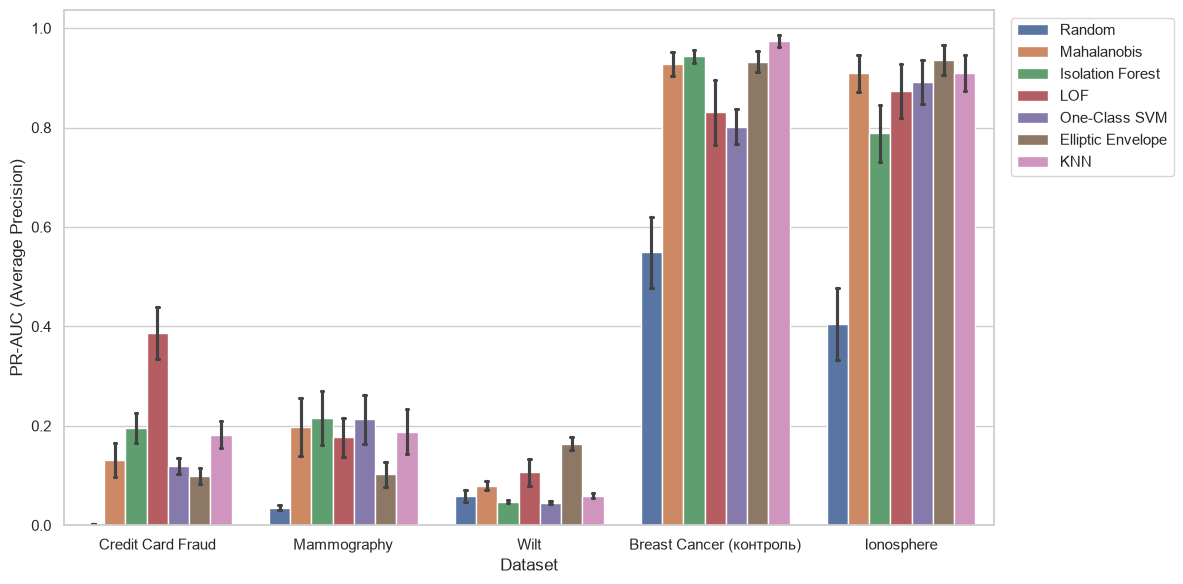

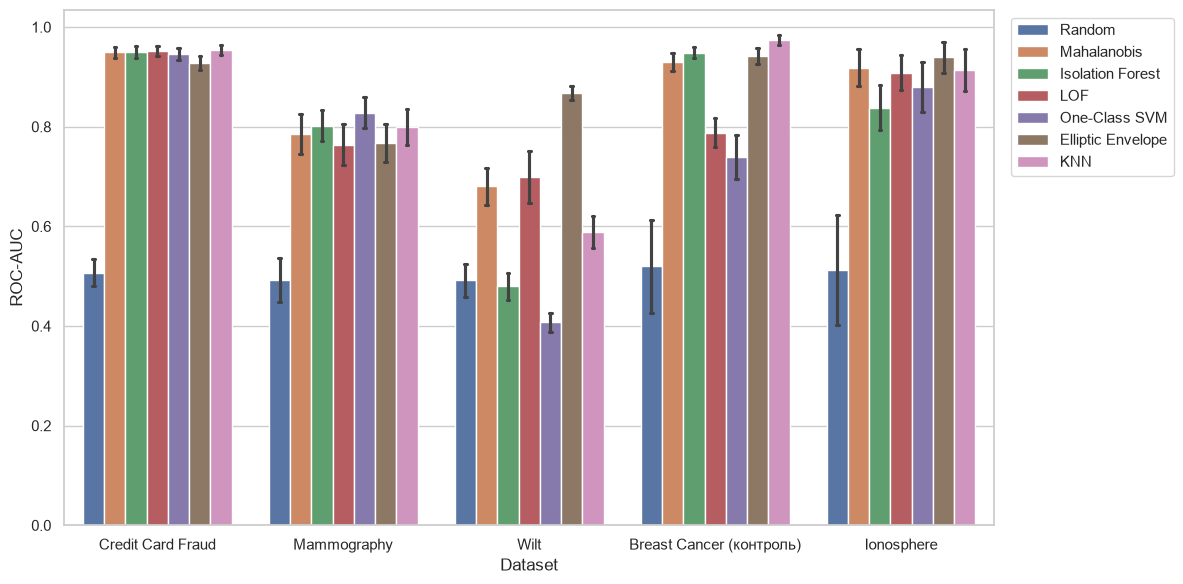

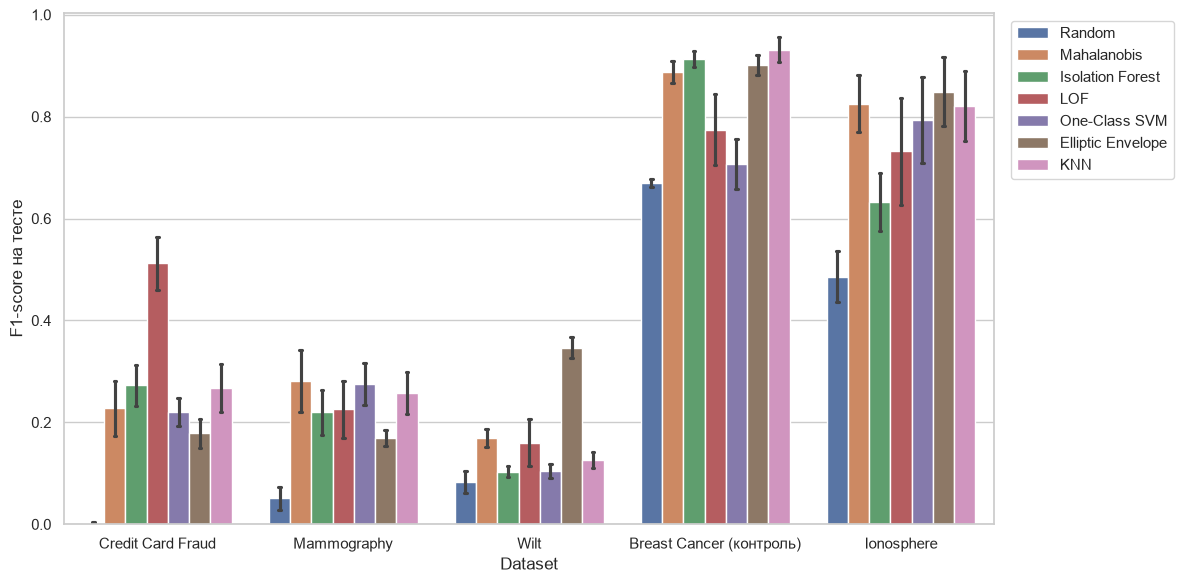

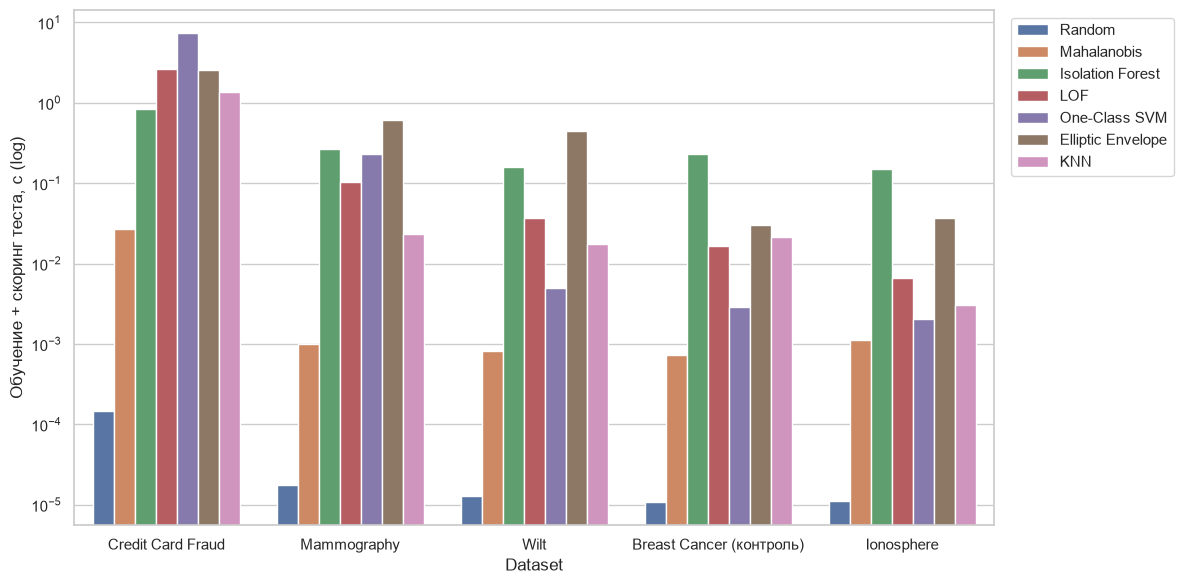

In [6]:
fmt = lambda x: f"{x.mean():.3f} ± {x.std():.3f}"
cols = ['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall', 'F1 (порог по доле)', 'Naive F1']
agg_df = df_results.groupby(['Dataset', 'Algorithm']).agg(
    {**{c: fmt for c in cols}, 'Fit Time (s)': 'mean', 'Score Time (s)': 'mean', 'Tuning Time (s)': 'mean'}).reset_index()
agg_df.to_csv('anomaly_detection_results_final.csv', index=False, encoding='utf-8-sig')
print("\n=== ИТОГОВАЯ ТАБЛИЦА ===")
display(agg_df)

# какие значения гиперпараметров выбирались (нужно, чтобы увидеть выбор на границе сетки)
bp = df_results.groupby(['Dataset', 'Algorithm'])['Best params'].agg(lambda s: s.value_counts().to_dict()).reset_index()
bp.to_csv('best_params_frequency.csv', index=False, encoding='utf-8-sig')
print("\n=== ВЫБРАННЫЕ ГИПЕРПАРАМЕТРЫ (частота по seed) ===")
for _, r in bp[~bp['Algorithm'].isin(['Random', 'Mahalanobis'])].iterrows():
    print(f"{r['Dataset']:28s} {r['Algorithm']:18s} {r['Best params']}")

# парный тест Вилкоксона по PR-AUC: лучший метод (без Random) против остальных
rows = []
for ds, g in df_results.groupby('Dataset'):
    means = g[g.Algorithm != 'Random'].groupby('Algorithm')['PR-AUC'].mean()
    best_algo = means.idxmax()
    ref = g[g.Algorithm == best_algo].set_index('Run')['PR-AUC']
    for algo in means.index:
        if algo == best_algo: continue
        oth = g[g.Algorithm == algo].set_index('Run')['PR-AUC']
        common = ref.index.intersection(oth.index)
        try:    p = wilcoxon(ref[common], oth[common]).pvalue
        except ValueError: p = np.nan
        rows.append({'Dataset': ds, 'Лучший': best_algo, 'Сравнивается с': algo,
                     'ΔPR-AUC': round(ref[common].mean() - oth[common].mean(), 3), 'p (Wilcoxon)': round(p, 4)})
wil = pd.DataFrame(rows)
wil.to_csv('wilcoxon_pr_auc.csv', index=False, encoding='utf-8-sig')
print("\n=== Парные тесты по PR-AUC (разбиения пересекаются, p — ориентир, не строгая значимость) ===")
display(wil)

# средние ранги по PR-AUC (только задачи с настоящими аномалиями, без Random)
anom = [d for d in df_results['Dataset'].unique() if d != CONTROL]
pv = (df_results[df_results.Dataset.isin(anom) & (df_results.Algorithm != 'Random')]
      .groupby(['Dataset', 'Algorithm'])['PR-AUC'].mean().unstack())
print("\n=== Средний ранг по PR-AUC (1 = лучший) ===")
print(pv.rank(axis=1, ascending=False).mean().sort_values().round(2))

# графики
df_results['Fit+Score Time (s)'] = df_results['Fit Time (s)'] + df_results['Score Time (s)']
order = [a for a in algorithms]
def bar(metric, fname, ylabel, logy=False):
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_results, x='Dataset', y=metric, hue='Algorithm', hue_order=order,
                errorbar=None if logy else 'sd', capsize=0.1)
    if logy: plt.yscale('log')
    plt.ylabel(ylabel); plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left'); plt.tight_layout()
    plt.savefig(fname, dpi=200); plt.show()
bar('PR-AUC', 'fig_pr_auc.png', 'PR-AUC (Average Precision)')
bar('ROC-AUC', 'fig_roc_auc.png', 'ROC-AUC')
bar('F1', 'fig_f1.png', 'F1-score на тесте')
bar('Fit+Score Time (s)', 'fig_time.png', 'Обучение + скоринг теста, с (log)', logy=True)